# 01 · Python Data Structures

The building blocks every Python program is made of: the four core collections, the specialised
containers in the standard library, functions, a first look at classes, comprehensions and error
handling. Every example is short and runnable; change it and run it again.

**You will learn**
1. Lists, tuples, dictionaries and sets, and when to use each one
2. The `collections` module: `deque`, `Counter`, `defaultdict`, `namedtuple`
3. Functions: default arguments, `*args`, `**kwargs`, lambdas
4. Classes in five minutes (module 05 goes much deeper)
5. Comprehensions and generators
6. Exceptions
7. Why the choice of structure matters: measuring lookup speed

## 1. Lists
Ordered, **mutable** and allow duplicates. The default container for "a sequence of things".

In [1]:
fruits = ["apple", "banana", "cherry"]
fruits.append("date")             # add at the end
fruits.insert(1, "apricot")       # add at a position
fruits.remove("banana")           # remove the first matching value
last = fruits.pop()               # remove and return the last item
print(fruits, "| popped:", last)

# slicing: [start:stop:step], stop is excluded
nums = list(range(10))
print(nums[2:5], nums[::2], nums[::-1])

# sorting: sorted() returns a new list, .sort() sorts in place
words = ["pear", "Fig", "apple"]
print(sorted(words), sorted(words, key=str.lower), sorted(words, key=len, reverse=True))

['apple', 'apricot', 'cherry'] | popped: date
[2, 3, 4] [0, 2, 4, 6, 8] [9, 8, 7, 6, 5, 4, 3, 2, 1, 0]
['Fig', 'apple', 'pear'] ['apple', 'Fig', 'pear'] ['apple', 'pear', 'Fig']


## 2. Tuples
Ordered and **immutable**. Use them for fixed groups of values (a point, a database row) and to return
several values from a function. Being immutable, they can be dictionary keys or set members.

In [2]:
point = (3, 4)
single = ("only_one",)            # the trailing comma makes it a tuple
x, y = point                      # unpacking
print(point, single, x, y)

def min_max(values):
    return min(values), max(values)   # returns a tuple

lo, hi = min_max([7, 2, 9, 4])
print(lo, hi)

first, *middle, last = [1, 2, 3, 4, 5]   # extended unpacking
print(first, middle, last)

(3, 4) ('only_one',) 3 4
2 9
1 [2, 3, 4] 5


## 3. Dictionaries
Key-value pairs, mutable, and insertion-ordered since Python 3.7. Lookup by key is fast, independent of
the dictionary's size.

In [3]:
person = {"name": "Alice", "age": 30, "city": "Berlin"}
person["age"] = 31                       # update
person["email"] = "alice@example.com"    # add
print(person.get("phone", "n/a"))        # safe access with a default
for key, value in person.items():
    print(f"{key:>6}: {value}")

# merging and dict comprehensions
defaults = {"city": "Unknown", "active": True}
merged = defaults | person               # right-hand side wins (Python 3.9+)
squares = {n: n * n for n in range(5)}
print(merged, squares)

n/a
  name: Alice
   age: 31
  city: Berlin
 email: alice@example.com
{'city': 'Berlin', 'active': True, 'name': 'Alice', 'age': 31, 'email': 'alice@example.com'} {0: 0, 1: 1, 2: 4, 3: 9, 4: 16}


## 4. Sets
Unordered, mutable, **unique** elements. Ideal for membership tests and removing duplicates.

In [4]:
a, b = {1, 2, 3}, {3, 4, 5}
print(a | b, a & b, a - b, a ^ b)        # union, intersection, difference, symmetric difference

nums = [1, 2, 2, 3, 3, 3]
print(sorted(set(nums)))                 # dedup (sets do not keep order, so sort if you need one)
print(3 in a, frozenset(a))              # frozenset: immutable set, usable as a dict key

{1, 2, 3, 4, 5} {3} {1, 2} {1, 2, 4, 5}
[1, 2, 3]
True frozenset({1, 2, 3})


## 5. Specialised containers: `collections`
The standard library has ready-made structures for common patterns. Reaching for them makes code shorter
and often faster.

| Structure | Use it for |
|---|---|
| `deque` | queues and sliding windows: fast append/pop at **both** ends |
| `Counter` | counting things |
| `defaultdict` | grouping without "if key not in dict" checks |
| `namedtuple` | lightweight records with named fields |
| `heapq` (module) | always getting the smallest item: priority queues, top-k |

In [5]:
from collections import deque, Counter, defaultdict, namedtuple
import heapq

window = deque(maxlen=3)                 # keeps only the last 3 items
for reading in [10, 12, 11, 15, 14]:
    window.append(reading)
print("last 3 readings:", list(window), "mean:", sum(window) / len(window))

text = "the quick brown fox jumps over the lazy dog the end"
print(Counter(text.split()).most_common(2))

by_letter = defaultdict(list)
for word in ["apple", "avocado", "banana", "blueberry", "cherry"]:
    by_letter[word[0]].append(word)
print(dict(by_letter))

City = namedtuple("City", ["name", "population_m"])
cities = [City("Tokyo", 37.4), City("Delhi", 32.9), City("Shanghai", 29.2), City("Madrid", 6.8)]
print(heapq.nlargest(2, cities, key=lambda c: c.population_m))

last 3 readings: [11, 15, 14] mean: 13.333333333333334
[('the', 3), ('quick', 1)]
{'a': ['apple', 'avocado'], 'b': ['banana', 'blueberry'], 'c': ['cherry']}
[City(name='Tokyo', population_m=37.4), City(name='Delhi', population_m=32.9)]


## 6. Functions
Reusable blocks of code. Type hints document what goes in and out; Python does not enforce them at run
time, but editors and checkers such as `mypy` use them.

In [6]:
def greet(name: str, greeting: str = "Hello") -> str:
    return f"{greeting}, {name}!"

print(greet("Alice"), greet("Bob", greeting="Hi"))

def total(*args: float) -> float:          # any number of positional arguments
    return sum(args)

def describe(**kwargs) -> str:             # any number of keyword arguments
    return ", ".join(f"{k}={v}" for k, v in kwargs.items())

print(total(1, 2, 3), "|", describe(colour="red", size="M"))

square = lambda n: n ** 2                   # small anonymous function
print(list(map(square, [1, 2, 3])), sorted(["bb", "a", "ccc"], key=lambda s: -len(s)))

Hello, Alice! Hi, Bob!
6 | colour=red, size=M
[1, 4, 9] ['ccc', 'bb', 'a']


**A classic trap: mutable default arguments.** The default value is created once, when the function is
defined, not on every call.

In [7]:
def add_item_bad(item, items=[]):
    items.append(item)
    return items

def add_item_good(item, items=None):
    items = [] if items is None else items
    items.append(item)
    return items

print(add_item_bad("a"), add_item_bad("b"))     # the same list is reused: ['a', 'b'] twice
print(add_item_good("a"), add_item_good("b"))

['a', 'b'] ['a', 'b']
['a'] ['b']


## 7. Classes in five minutes
A class is a blueprint, an object is one instance of it, and methods are functions that belong to the
class. Module 05 covers object-oriented programming in depth; this is just enough to read code that uses it.

In [8]:
class Dog:
    species = "Canis familiaris"            # class attribute: shared by every dog

    def __init__(self, name: str, age: int):
        self.name = name                    # instance attributes: one per dog
        self.age = age

    def speak(self) -> str:
        return f"{self.name} says woof"

    def __repr__(self) -> str:              # how the object prints
        return f"Dog(name={self.name!r}, age={self.age})"

rex = Dog("Rex", 4)
print(rex, rex.speak(), Dog.species)

Dog(name='Rex', age=4) Rex says woof Canis familiaris


## 8. Comprehensions and generators
Comprehensions build a collection in one readable line. A **generator** produces values lazily, one at a
time, so it uses almost no memory even for millions of items. That idea returns in module 03.

In [9]:
import sys

squares = [n ** 2 for n in range(10) if n % 2 == 0]
pairs = [(x, y) for x in range(3) for y in "ab"]
print(squares, pairs)

big_list = [n for n in range(1_000_000)]
big_gen = (n for n in range(1_000_000))
print(f"list: {sys.getsizeof(big_list) / 1e6:.1f} MB, generator: {sys.getsizeof(big_gen)} bytes")
print("sum from the generator:", sum(big_gen))

def countdown(n):
    while n > 0:
        yield n          # 'yield' makes this function a generator
        n -= 1

print(list(countdown(5)))

[0, 4, 16, 36, 64] [(0, 'a'), (0, 'b'), (1, 'a'), (1, 'b'), (2, 'a'), (2, 'b')]
list: 8.4 MB, generator: 192 bytes


sum from the generator:

 499999500000
[5, 4, 3, 2, 1]


## 9. Exceptions
Handle the errors you expect, let the unexpected ones surface. `else` runs only when nothing failed,
`finally` always runs (cleanup).

In [10]:
def divide(a, b):
    try:
        result = a / b
    except ZeroDivisionError:
        print("cannot divide by zero")
        return None
    except TypeError as e:
        print("bad input:", e)
        return None
    else:
        return result
    finally:
        print(f"divide({a!r}, {b!r}) finished")

print(divide(10, 2), divide(1, 0), divide("a", 1))

class InsufficientFunds(Exception):
    '''A custom exception makes the failure explicit for the caller.'''

try:
    raise InsufficientFunds("balance 10, requested 50")
except InsufficientFunds as e:
    print("caught:", e)

divide(10, 2) finished
cannot divide by zero
divide(1, 0) finished
bad input: unsupported operand type(s) for /: 'str' and 'int'
divide('a', 1) finished
5.0 None None
caught: balance 10, requested 50


## 10. Why the choice of structure matters
Checking whether an item is **in** a list scans it item by item (time grows with the size, O(n)). A set
or dict uses hashing and answers in about the same time whatever its size (O(1) on average). Measured:

n=    1,000  list:       13.1 µs   set:   0.16 µs
n=   10,000  list:      135.7 µs   set:   0.15 µs
n=  100,000  list:     1413.8 µs   set:   0.16 µs
n=1,000,000  list:    14831.2 µs   set:   0.17 µs


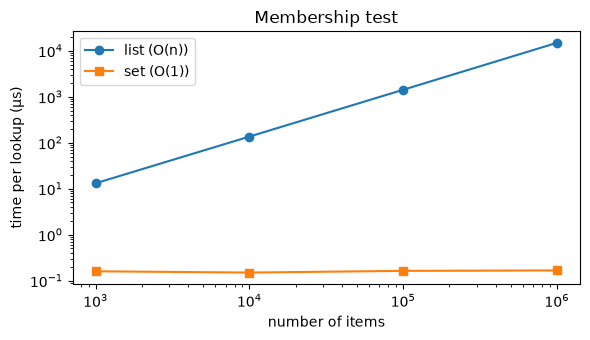

In [11]:
import timeit
import matplotlib.pyplot as plt

sizes = [1_000, 10_000, 100_000, 1_000_000]
t_list, t_set = [], []
for n in sizes:
    data_list = list(range(n))
    data_set = set(data_list)
    target = n - 1                          # worst case for the list: the last element
    t_list.append(timeit.timeit(lambda: target in data_list, number=50) / 50 * 1e6)
    t_set.append(timeit.timeit(lambda: target in data_set, number=50) / 50 * 1e6)

for n, a, b in zip(sizes, t_list, t_set):
    print(f"n={n:>9,}  list: {a:10.1f} µs   set: {b:6.2f} µs")

plt.figure(figsize=(6, 3.5))
plt.loglog(sizes, t_list, "o-", label="list (O(n))")
plt.loglog(sizes, t_set, "s-", label="set (O(1))")
plt.xlabel("number of items"); plt.ylabel("time per lookup (µs)"); plt.legend(); plt.title("Membership test")
plt.tight_layout(); plt.show()

| Operation | list | tuple | dict | set |
|---|---|---|---|---|
| ordered | yes | yes | yes (insertion) | no |
| mutable | yes | no | yes | yes |
| duplicates | yes | yes | keys unique | no |
| `x in c` | O(n) | O(n) | O(1) on keys | O(1) |
| typical use | sequences | fixed records | lookups by key | membership, dedup |

## Exercises
1. Given a list of words, return the five most frequent with their counts (one line with `Counter`).
2. Group a list of `(student, grade)` tuples into a dict `grade -> [students]` with `defaultdict`.
3. Write a generator `fibonacci()` that yields the sequence forever, and print the first 15 values with `itertools.islice`.
4. Repeat the timing experiment with a `dict` and a `tuple`. Which behaves like a list and which like a set?